# Project Title: Apartment Rent Prediction Using Artificial Neural Networks (ANN)

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

### Load and inspect the apartment rental dataset

In [2]:
# Load the apartment rental dataset
df = pd.read_csv(r"C:\Users\jayes\OneDrive\Desktop\Imarticus Learning\Assignment\Deep Learning & AI\Project on ANN\Apartment_Rent_Dataset - LMS.csv")

In [3]:
# Display the number of rows and columns
print("Dataset Shape:", df.shape)

Dataset Shape: (9458, 20)


In [4]:
# Display all column names
print(df.columns.tolist())


['listing_id', 'city', 'locality', 'property_type', 'bhk', 'bathrooms', 'builtup_sqft', 'carpet_area_sqft', 'floor_number', 'total_floors', 'building_age_years', 'furnishing', 'parking_slots', 'gated_society', 'amenities_score', 'metro_distance_km', 'commute_time_to_business_district_min', 'maintenance_included', 'power_backup', 'monthly_rent_inr']


In [5]:
# Display the first 5 records
display(df.head())

,listing_id,city,locality,property_type,bhk,bathrooms,builtup_sqft,carpet_area_sqft,floor_number,total_floors,building_age_years,furnishing,parking_slots,gated_society,amenities_score,metro_distance_km,commute_time_to_business_district_min,maintenance_included,power_backup,monthly_rent_inr
0,HSG-966691-04078,Bengaluru,Yelahanka,Apartment,3,3,978,848.0,5,8,14,Unfurnished,1.0,0,48.0,NaN,119,Yes,Partial,36440
1,HSG-637024-04132,Chennai,Porur,Builder Floor,2,3,460,411.0,1,4,16,Fully Furnished,1.0,1,53.0,1.56,58,No,Partial,11380
2,OLX-835407-07415,Surat,Pal,Apartment,3,4,1253,904.0,3,10,5,Semi-Furnished,1.0,0,61.0,NaN,40,No,Partial,55370
3,MB-833530-07023,Pune,Hadapsar,Apartment,3,4,906,717.0,4,12,6,Semi-Furnished,2.0,1,70.0,3.61,95,No,Full,51750
4,HSG-716103-05993,Bhubaneswar,Gajapati Nagar,Builder Floor,2,3,757,611.0,0,3,10,Unfurnished,1.0,1,51.0,NaN,77,No,Partial,10290


In [6]:
# Display dataset information and data types
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9458 entries, 0 to 9457
Data columns (total 20 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   listing_id                             9458 non-null   object 
 1   city                                   9458 non-null   object 
 2   locality                               9458 non-null   object 
 3   property_type                          9458 non-null   object 
 4   bhk                                    9458 non-null   int64  
 5   bathrooms                              9458 non-null   int64  
 6   builtup_sqft                           9458 non-null   int64  
 7   carpet_area_sqft                       8613 non-null   float64
 8   floor_number                           9458 non-null   int64  
 9   total_floors                           9458 non-null   int64  
 10  building_age_years                     9458 non-null   int64  
 11  furn

### Check missing values, duplicates, and invalid records

In [7]:
# Check missing values in each column
print(df.isnull().sum())

listing_id                                  0
city                                        0
locality                                    0
property_type                               0
bhk                                         0
bathrooms                                   0
builtup_sqft                                0
carpet_area_sqft                          845
floor_number                                0
total_floors                                0
building_age_years                          0
furnishing                                  0
parking_slots                             471
gated_society                               0
amenities_score                          1329
metro_distance_km                        2899
commute_time_to_business_district_min       0
maintenance_included                        0
power_backup                             4397
monthly_rent_inr                            0
dtype: int64


In [8]:
df.isnull().sum()[df.isnull().sum() > 0]

carpet_area_sqft      845
parking_slots         471
amenities_score      1329
metro_distance_km    2899
power_backup         4397
dtype: int64

In [9]:
# Check total missing values
print("Total Missing Values:", df.isnull().sum().sum())

Total Missing Values: 9941


In [10]:
# Check exact duplicate rows
print("Exact Duplicate Rows:", df.duplicated().sum())

Exact Duplicate Rows: 158


In [11]:
# Check duplicate listing IDs
print("Duplicate Listing IDs:", df["listing_id"].duplicated().sum())

Duplicate Listing IDs: 158


In [12]:
# Check whether the target contains zero or negative rent
print("Zero or Negative Rent Records:",(df["monthly_rent_inr"] <= 0).sum())


Zero or Negative Rent Records: 0


In [13]:
# Check numerical summary statistics
print("Numerical Summary:"),display(df.describe().T)


Numerical Summary:


,count,mean,std,min,25%,50%,75%,max
bhk,9458.0,2.542609,0.707019,1.0,2.00,3.00,3.00,4.00
bathrooms,9458.0,3.043350,0.873168,1.0,2.00,3.00,4.00,5.00
builtup_sqft,9458.0,952.435293,443.035397,280.0,634.00,858.50,1168.00,3500.00
carpet_area_sqft,8613.0,742.978637,352.468645,200.0,490.00,669.00,910.00,3001.00
floor_number,9458.0,5.192218,4.594093,0.0,2.00,4.00,8.00,32.00
total_floors,9458.0,12.584584,7.579328,1.0,5.00,12.00,18.00,38.00
building_age_years,9458.0,14.725946,10.170460,0.0,7.00,13.00,20.00,60.00
parking_slots,8987.0,0.993101,0.570977,0.0,1.00,1.00,1.00,2.00
gated_society,9458.0,0.581624,0.493319,0.0,0.00,1.00,1.00,1.00
amenities_score,8129.0,50.192398,16.851376,0.0,38.00,51.00,62.00,100.00


(None, None)

----------------------------------------------------------------------------------------------------------------
**Key observations**

- power_backup: 4,397 missing values, about 46.5% of records.
- metro_distance_km: 2,899 missing values, about 30.7%.
- amenities_score: 1,329 missing values.
- Duplicate records: 158 exact duplicate rows, and the same number of duplicate listing_id values. These likely correspond to the same duplicated rows, but we'll verify before removing them.
- Rent distribution: The mean rent is ₹58,410, while the median is ₹32,705. This suggests a right-skewed distribution, potentially influenced by high-rent properties.
----------------------------------------------------------------------------------------------------------------

### Exploratory Data Analysis (EDA)

In [15]:
# Display rent statistics
print("Monthly Rent Statistics:")
print(df["monthly_rent_inr"].describe())

Monthly Rent Statistics:
count      9458.000000
mean      58410.257983
std       73111.779794
min        4500.000000
25%       15390.000000
50%       32705.000000
75%       68607.500000
max      420000.000000
Name: monthly_rent_inr, dtype: float64


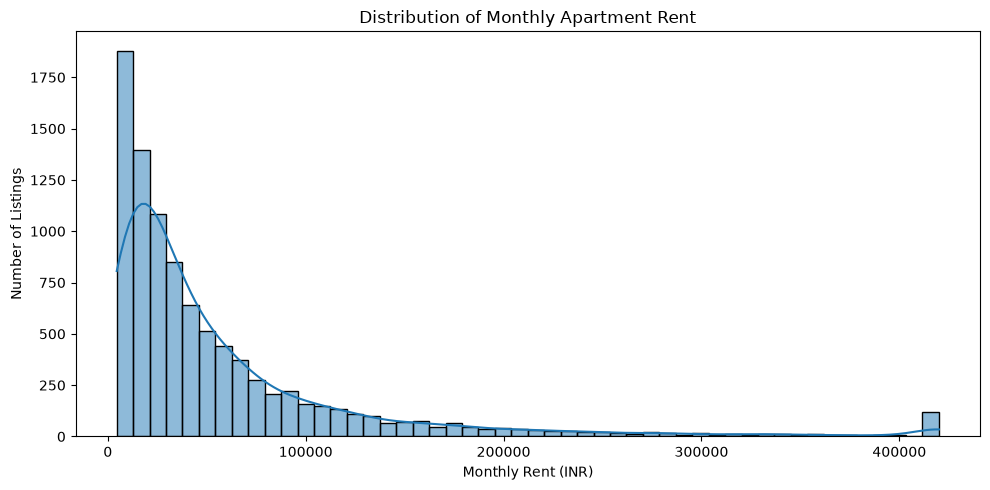

In [16]:
# Plot the distribution of monthly rent
plt.figure(figsize=(10, 5))
sns.histplot(df["monthly_rent_inr"], bins=50, kde=True)
plt.title("Distribution of Monthly Apartment Rent")
plt.xlabel("Monthly Rent (INR)")
plt.ylabel("Number of Listings")
plt.tight_layout()
plt.show()

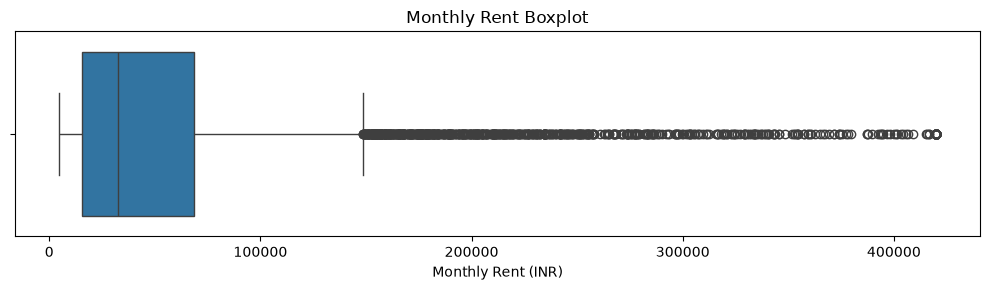

In [17]:
# Plot a boxplot to identify potential outliers
plt.figure(figsize=(10, 3))
sns.boxplot(x=df["monthly_rent_inr"])
plt.title("Monthly Rent Boxplot")
plt.xlabel("Monthly Rent (INR)")
plt.tight_layout()
plt.show()


**Key Findings**
- Most listings are concentrated in the lower rent ranges.
- The mean rent (₹58,410) is higher than the median (₹32,705), consistent with right-skewness.
- Some listings approach ₹420,000 per month and should be investigated.

In [18]:
# Analyze monthly rent by city

city_rent = (
    df.groupby("city")["monthly_rent_inr"]
    .agg(["count", "mean", "median"])
    .sort_values("median", ascending=False)
)

print("Rent Statistics by City:")
display(city_rent.round(2))

Rent Statistics by City:


,count,mean,median
city,,,
Mumbai,965,127525.92,87120.0
Gurugram,383,67185.48,48770.0
Bengaluru,955,74242.64,45500.0
Delhi,905,66296.08,43380.0
Pune,694,65847.10,41345.0
Noida,409,67038.51,41150.0
Chennai,612,62056.60,38790.0
Hyderabad,693,60490.84,37000.0
Ahmedabad,398,40907.36,25995.0


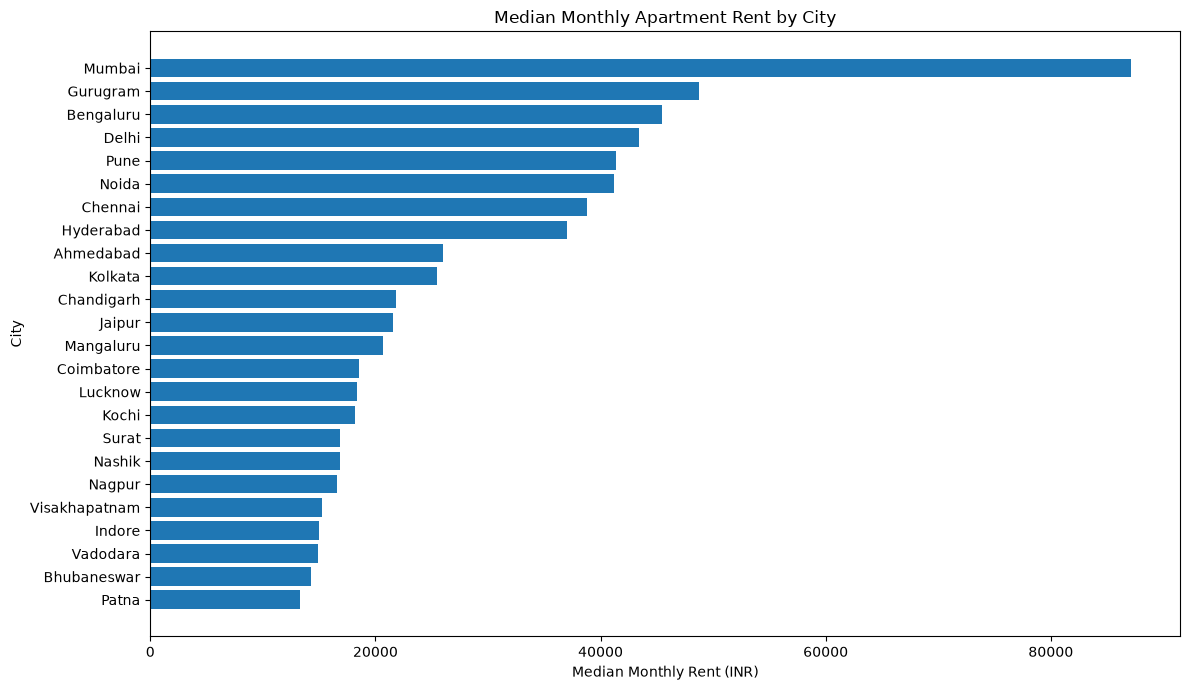

In [19]:
# Plot median rent by city
plt.figure(figsize=(12, 7))

city_rent_sorted = city_rent.sort_values("median", ascending=True)

plt.barh(
    city_rent_sorted.index,
    city_rent_sorted["median"]
)

plt.title("Median Monthly Apartment Rent by City")
plt.xlabel("Median Monthly Rent (INR)")
plt.ylabel("City")
plt.tight_layout()
plt.show()


----------------------------------------------------------------------------------------------------------------
**Business interpretation**
- Mumbai: Highest median rent in your analysis, suggesting that apartments in this city tend to be more expensive.
- Patna: Lowest median rent in your analysis, suggesting comparatively lower rental prices.
- Differences between cities: The substantial variation supports including city as an input feature in our ANN.
----------------------------------------------------------------------------------------------------------------

In [20]:
# Calculate correlation between built-up area and rent
correlation = df["builtup_sqft"].corr(df["monthly_rent_inr"])

print("Correlation between Built-up Area and Monthly Rent:",round(correlation, 3))

Correlation between Built-up Area and Monthly Rent: 0.727


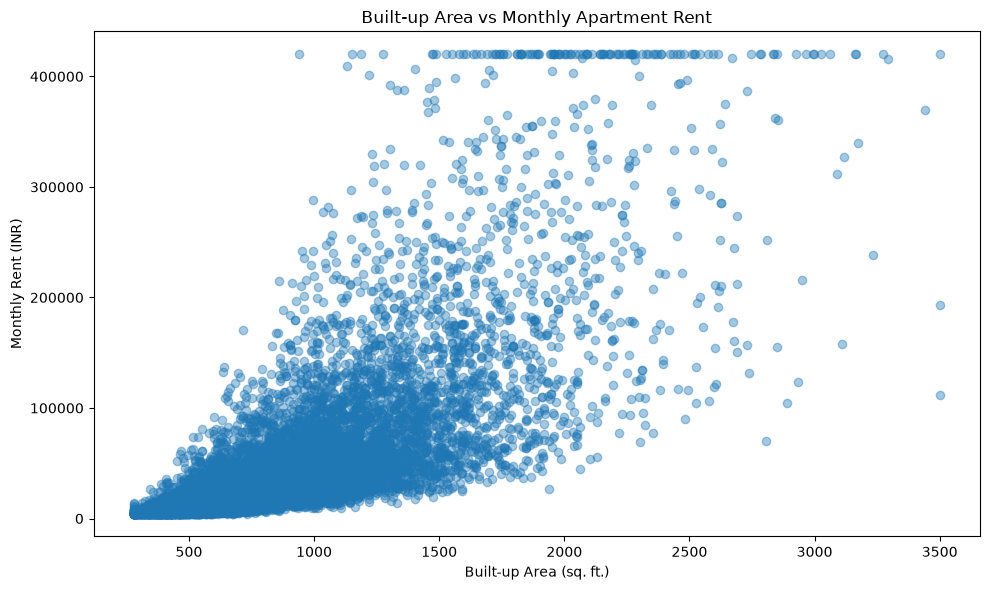

In [21]:
# Scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    df["builtup_sqft"],
    df["monthly_rent_inr"],
    alpha=0.4
)

plt.title("Built-up Area vs Monthly Apartment Rent")
plt.xlabel("Built-up Area (sq. ft.)")
plt.ylabel("Monthly Rent (INR)")
plt.tight_layout()
plt.show()


Median Rent by BHK:


bhk
1      6140.0
2     17540.0
3     53935.0
4    206735.0
Name: monthly_rent_inr, dtype: float64

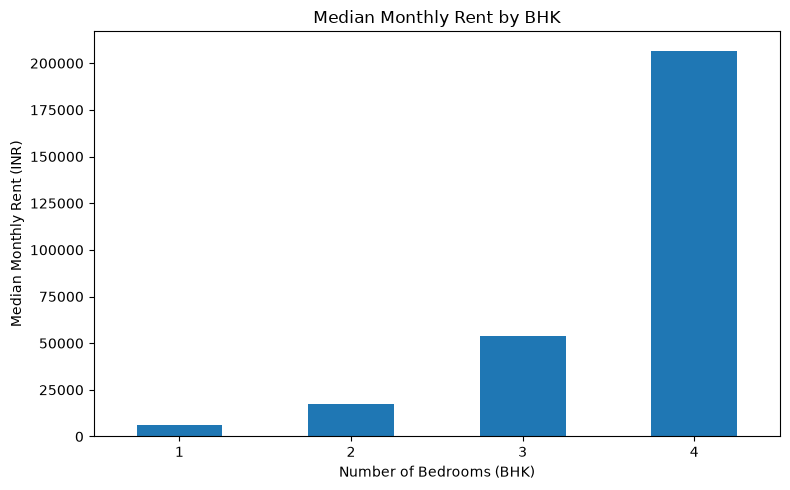

In [22]:
# Compare median rent by BHK
bhk_rent = df.groupby("bhk")["monthly_rent_inr"].median()

print("\nMedian Rent by BHK:")
display(bhk_rent)

# Plot median rent by BHK
plt.figure(figsize=(8, 5))
bhk_rent.plot(kind="bar")
plt.title("Median Monthly Rent by BHK")
plt.xlabel("Number of Bedrooms (BHK)")
plt.ylabel("Median Monthly Rent (INR)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


----------------------------------------------------------------------------------------------------------------
**Interpretation of results:**
*Correlation*: Built-up area vs monthly rent - 0.727
    - This indicates a strong positive linear association: larger built-up areas generally tend to have higher rents in this dataset.

*What plots tell us*
- Built-up area: The scatter plot shows rent generally increasing with apartment size, although the spread widens for larger apartments.
- BHK: Your median-rent chart shows increasing rent across the 1, 2, 3, and 4 BHK categories.
- High-rent listings: Some properties have high rents even at moderate sizes, suggesting other factors—such as city, locality, furnishing, and amenities—also matter.
----------------------------------------------------------------------------------------------------------------

In [23]:
# Analyze rent by property type and furnishing
# Median rent by property type

property_rent = (
    df.groupby("property_type")["monthly_rent_inr"]
    .median()
    .sort_values(ascending=False)
)

print("Median Rent by Property Type:")
display(property_rent)



Median Rent by Property Type:


property_type
Penthouse        282955.0
Apartment         34440.0
Builder Floor     28780.0
Studio             4700.0
Name: monthly_rent_inr, dtype: float64

In [24]:
# Median rent by furnishing status

furnishing_rent = (
    df.groupby("furnishing")["monthly_rent_inr"]
    .median()
    .sort_values(ascending=False)
)

print("Median Rent by Furnishing:")
display(furnishing_rent)

Median Rent by Furnishing:


furnishing
Fully Furnished    50965.0
Semi-Furnished     36460.0
Unfurnished        26850.0
Name: monthly_rent_inr, dtype: float64

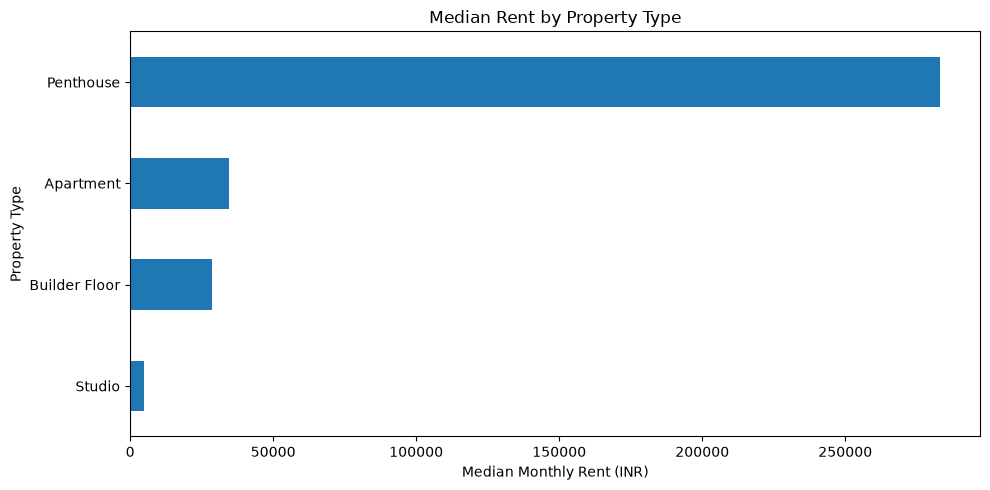

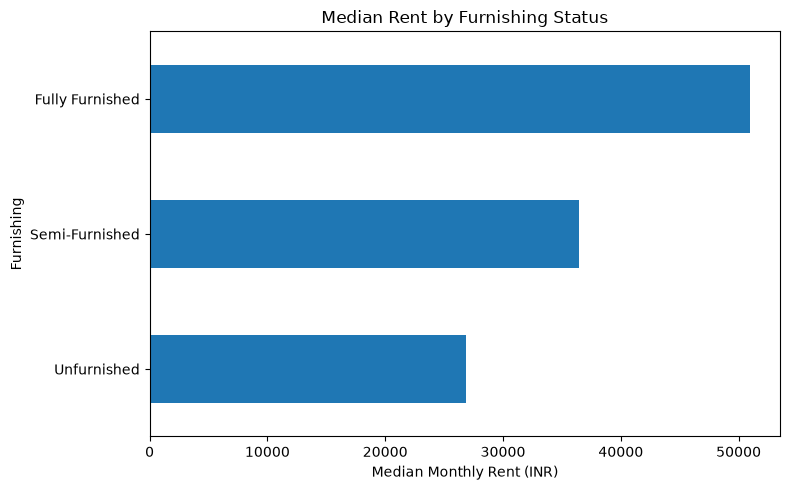

In [25]:
# Visualize rent by property type
plt.figure(figsize=(10, 5))
property_rent.sort_values().plot(kind="barh")
plt.title("Median Rent by Property Type")
plt.xlabel("Median Monthly Rent (INR)")
plt.ylabel("Property Type")
plt.tight_layout()
plt.show()

# Visualize rent by furnishing
plt.figure(figsize=(8, 5))
furnishing_rent.sort_values().plot(kind="barh")
plt.title("Median Rent by Furnishing Status")
plt.xlabel("Median Monthly Rent (INR)")
plt.ylabel("Furnishing")
plt.tight_layout()
plt.show()


----------------------------------------------------------------------------------------------------------------
**Interpretation of results:**

*Median rent by property type*

        Property type  Median monthly rent
        Penthouse	      ₹2,82,955
        Apartment	      ₹34,440
        Builder Floor     ₹28,780
        Studio	      ₹4,700

- Penthouses have a much higher median rent than the other property types. However, we should check the number of listings in each category before drawing strong conclusions, because a category with very few records may be less representative.

*Median rent by furnishing*

        Furnishing status	Median monthly rent
        Fully Furnished	₹50,965
        Semi-Furnished	₹36,460
        Unfurnished	        ₹26,850

- The median rent increases with furnishing level in your dataset. This suggests furnishing may help the ANN learn differences between properties with different furnishing levels.
----------------------------------------------------------------------------------------------------------------

In [26]:
# Check category counts

print("Number of listings by property type:")
display(df["property_type"].value_counts())

print("\nNumber of listings by furnishing status:")
display(df["furnishing"].value_counts())

print("\nNumber of listings by city:")
display(df["city"].value_counts())

Number of listings by property type:


property_type
Apartment        7225
Builder Floor    1991
Studio            148
Penthouse          94
Name: count, dtype: int64


Number of listings by furnishing status:


furnishing
Unfurnished        5137
Semi-Furnished     2675
Fully Furnished    1646
Name: count, dtype: int64


Number of listings by city:


city
Mumbai           965
Bengaluru        955
Delhi            905
Pune             694
Hyderabad        693
Chennai          612
Kolkata          508
Noida            409
Ahmedabad        398
Gurugram         383
Jaipur           293
Lucknow          289
Mangaluru        208
Visakhapatnam    204
Vadodara         201
Kochi            201
Nagpur           199
Surat            198
Patna            196
Indore           193
Coimbatore       193
Chandigarh       190
Bhubaneswar      189
Nashik           182
Name: count, dtype: int64

In [27]:
# Check rent statistics for each property type

print("\nRent statistics by property type:")
display(
    df.groupby("property_type")["monthly_rent_inr"]
    .agg(["count", "median", "mean", "min", "max"])
    .sort_values("median", ascending=False)
    .round(2)
)



Rent statistics by property type:


,count,median,mean,min,max
property_type,,,,,
Penthouse,94,282955.0,278651.49,75010,420000
Apartment,7225,34440.0,59129.22,4500,420000
Builder Floor,1991,28780.0,49245.95,4500,420000
Studio,148,4700.0,6713.99,4500,30930


----------------------------------------------------------------------------------------------------------------
**Key findings**
- Apartments: 7,225 listings — the dominant category.
- Builder Floors: 1,991 listings.
- Studios: 148 listings.
- Penthouses: 94 listings — a small category, but with a median rent of ₹2,82,955

    - The Penthouse category represents only about 1% of all records. We should retain it for now because it is a valid property type, but evaluate model performance carefully for high-rent listings.
    - Furnishing categories are also reasonably represented, and each of the 24 cities has more than 180 records. This is useful for encoding categorical variables later.
----------------------------------------------------------------------------------------------------------------

**Investigate duplicate records**

In [28]:
# Count exact duplicate rows

exact_duplicates = df.duplicated().sum()

# Count duplicate listing IDs
duplicate_ids = df["listing_id"].duplicated().sum()

print("Exact duplicate rows:", exact_duplicates)
print("Duplicate listing IDs:", duplicate_ids)

Exact duplicate rows: 158
Duplicate listing IDs: 158


In [29]:
# Display rows with repeated listing IDs
repeated_id_rows = df[
    df["listing_id"].duplicated(keep=False)
].sort_values("listing_id")

print("\nRows with repeated listing IDs:")
display(repeated_id_rows.head(10))


Rows with repeated listing IDs:


,listing_id,city,locality,property_type,bhk,bathrooms,builtup_sqft,carpet_area_sqft,floor_number,total_floors,building_age_years,furnishing,parking_slots,gated_society,amenities_score,metro_distance_km,commute_time_to_business_district_min,maintenance_included,power_backup,monthly_rent_inr
5548,99A-100033-09259,Chennai,Tambaram,Apartment,3,4,966,835.0,5,19,42,Unfurnished,1.0,0,33.0,3.18,34,No,NaN,17910
2745,99A-100033-09259,Chennai,Tambaram,Apartment,3,4,966,835.0,5,19,42,Unfurnished,1.0,0,33.0,3.18,34,No,NaN,17910
30,99A-111734-01046,Bengaluru,Indiranagar,Apartment,3,3,811,640.0,9,18,1,Fully Furnished,1.0,1,76.0,NaN,55,Yes,Full,67400
7167,99A-111734-01046,Bengaluru,Indiranagar,Apartment,3,3,811,640.0,9,18,1,Fully Furnished,1.0,1,76.0,NaN,55,Yes,Full,67400
8921,99A-172412-01992,Hyderabad,Kukatpally,Apartment,3,4,1523,1335.0,15,21,33,Unfurnished,0.0,0,25.0,2.59,38,No,NaN,80220
2077,99A-172412-01992,Hyderabad,Kukatpally,Apartment,3,4,1523,1335.0,15,21,33,Unfurnished,0.0,0,25.0,2.59,38,No,NaN,80220
3012,99A-182290-07093,Indore,Sudama Nagar,Apartment,2,3,717,591.0,6,11,3,Fully Furnished,1.0,1,72.0,NaN,37,Yes,Partial,30840
99,99A-182290-07093,Indore,Sudama Nagar,Apartment,2,3,717,591.0,6,11,3,Fully Furnished,1.0,1,72.0,NaN,37,Yes,Partial,30840
2256,99A-200739-05465,Lucknow,Jankipuram,Apartment,2,2,595,NaN,0,17,4,Unfurnished,0.0,0,51.0,4.28,64,Yes,NaN,9440
3451,99A-200739-05465,Lucknow,Jankipuram,Apartment,2,2,595,NaN,0,17,4,Unfurnished,0.0,0,51.0,4.28,64,Yes,NaN,9440


In [30]:
# Check whether repeated IDs have conflicting data
print("\nNumber of unique listing IDs:", df["listing_id"].nunique())
print("Total rows:", len(df))
print("Exact duplicate rows:", exact_duplicates)


Number of unique listing IDs: 9300
Total rows: 9458
Exact duplicate rows: 158


**Remove exact duplicate rows**

In [31]:
# Keep the original dataset unchanged
df_clean = df.copy()

In [32]:
# Check the number of rows before cleaning
print("Rows before cleaning:", len(df_clean))

Rows before cleaning: 9458


In [33]:
# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().copy()

In [34]:
# Reset the index after removing duplicates
df_clean = df_clean.reset_index(drop=True)

In [35]:
# Check the number of rows after cleaning
print("Rows after cleaning:", len(df_clean))

Rows after cleaning: 9300


In [36]:
# Verify remaining exact duplicates
print("Remaining exact duplicates:", df_clean.duplicated().sum())

Remaining exact duplicates: 0


In [37]:
# Verify unique listing IDs
print("Unique listing IDs:", df_clean["listing_id"].nunique())

Unique listing IDs: 9300


### Check invalid and inconsistent property values

In [38]:
#Check invalid property values

print("Checking invalid values in the cleaned dataset...\n")

# Check numerical values that should be positive
print("BHK <= 0:", (df_clean["bhk"] <= 0).sum())
print("Bathrooms <= 0:", (df_clean["bathrooms"] <= 0).sum())
print("Built-up area <= 0:", (df_clean["builtup_sqft"] <= 0).sum())
print("Total floors <= 0:", (df_clean["total_floors"] <= 0).sum())
print("Negative building age:",
      (df_clean["building_age_years"] < 0).sum())
print("Negative parking slots:",
      (df_clean["parking_slots"] < 0).sum())
print("Negative amenities score:",
      (df_clean["amenities_score"] < 0).sum())
print("Negative metro distance:",
      (df_clean["metro_distance_km"] < 0).sum())


Checking invalid values in the cleaned dataset...

BHK <= 0: 0
Bathrooms <= 0: 0
Built-up area <= 0: 0
Total floors <= 0: 0
Negative building age: 0
Negative parking slots: 0
Negative amenities score: 0
Negative metro distance: 0


In [39]:
# Check whether floor number exceeds total floors
invalid_floor = df_clean[
    df_clean["floor_number"] > df_clean["total_floors"]
]

print("Floor number greater than total floors:", len(invalid_floor))

Floor number greater than total floors: 27


In [40]:
# Check whether carpet area exceeds built-up area
invalid_area = df_clean[
    df_clean["carpet_area_sqft"] > df_clean["builtup_sqft"]
]

print("Carpet area greater than built-up area:", len(invalid_area))


Carpet area greater than built-up area: 42


----------------------------------------------------------------------------------------------------------------
**Interpret your results**

    Validation check	                          Flagged records	Decision
    
    BHK, bathrooms, built-up area	                          0	       No action needed
    Total floors, building age	                          0	       No action needed
    Negative parking, amenities, metro distance	          0	       No action needed
    Floor number exceeds total floors	                  27	         Investigate
    Carpet area exceeds built-up area	                  42	         Investigate
----------------------------------------------------------------------------------------------------------------

In [41]:
# Inspect inconsistent property records

# Check floor numbers greater than total floors
invalid_floor = df_clean[
    df_clean["floor_number"] > df_clean["total_floors"]
]

print("Records where floor number exceeds total floors:")
display(
    invalid_floor[
        ["listing_id", "city", "locality",
         "floor_number", "total_floors", "monthly_rent_inr"]
    ].head(15)
)

Records where floor number exceeds total floors:


,listing_id,city,locality,floor_number,total_floors,monthly_rent_inr
10,HSG-262269-01670,Hyderabad,Kondapur,27,26,15350
500,OLX-149551-03145,Gurugram,MG Road,12,10,16980
587,CL-803704-03651,Delhi,Janakpuri,23,21,52640
1058,HSG-231424-00185,Noida,Greater Noida West,18,15,44360
1349,CL-408691-07432,Jaipur,Shyam Nagar,6,4,12630
1420,OLX-173442-01414,Bengaluru,Sarjapur Road,13,11,14850
1499,HSG-171816-00393,Jaipur,Malviya Nagar,12,9,4500
2485,MB-843313-06838,Mangaluru,Attavar,18,16,27170
3013,NB-914648-06187,Delhi,Dwarka,17,14,13220
3093,CL-461482-06962,Ahmedabad,Vastrapur,22,19,116360


In [42]:
# Check carpet area greater than built-up area
invalid_area = df_clean[
    df_clean["carpet_area_sqft"] > df_clean["builtup_sqft"]
]

print("Records where carpet area exceeds built-up area:")
display(
    invalid_area[
        ["listing_id", "city", "locality",
         "builtup_sqft", "carpet_area_sqft", "monthly_rent_inr"]
    ].head(15)
)


Records where carpet area exceeds built-up area:


,listing_id,city,locality,builtup_sqft,carpet_area_sqft,monthly_rent_inr
50,HSG-878582-07596,Hyderabad,Manikonda,1075,1137.0,61500
197,NB-309130-09125,Patna,Danapur,1320,1384.0,32130
336,99A-722028-00286,Mumbai,Goregaon East,1424,1526.0,320040
458,MB-409536-06559,Delhi,Laxmi Nagar,1085,1143.0,55650
525,MB-428206-03128,Jaipur,Jagatpura,1788,1827.0,268400
560,OLX-212265-02879,Mumbai,Goregaon East,560,567.0,37970
787,OLX-276150-03662,Visakhapatnam,Gajuwaka,948,1039.0,13750
803,NB-394738-00353,Ahmedabad,Navrangpura,628,643.0,13880
1089,NB-743318-07998,Delhi,Laxmi Nagar,720,823.0,31420
1347,99A-322942-00385,Mangaluru,Pumpwell,559,562.0,7760


In [43]:
# Quantify property inconsistencies

# Calculate the difference between floor number and total floors
floor_issues = df_clean[
    df_clean["floor_number"] > df_clean["total_floors"]
].copy()

floor_issues["floor_difference"] = (
    floor_issues["floor_number"] - floor_issues["total_floors"]
)

print("Floor inconsistency summary:")
print("Number of records:", len(floor_issues))
print("Maximum floor difference:",
      floor_issues["floor_difference"].max())

display(floor_issues["floor_difference"].value_counts().sort_index())

Floor inconsistency summary:
Number of records: 27
Maximum floor difference: 3


floor_difference
1     9
2    12
3     6
Name: count, dtype: int64

In [44]:
# Calculate the difference between carpet and built-up area
area_issues = df_clean[
    df_clean["carpet_area_sqft"] > df_clean["builtup_sqft"]
].copy()

area_issues["area_difference"] = (
    area_issues["carpet_area_sqft"] - area_issues["builtup_sqft"]
)

print("\nCarpet area inconsistency summary:")
print("Number of records:", len(area_issues))
print("Maximum area difference (sq. ft.):",
      area_issues["area_difference"].max())

display(area_issues["area_difference"].describe())

# Confirm the original cleaned dataset remains unchanged
print("\nRows in df_clean:", len(df_clean))


Carpet area inconsistency summary:
Number of records: 42
Maximum area difference (sq. ft.): 141.0


count     42.000000
mean      53.238095
std       35.949022
min        1.000000
25%       25.750000
50%       50.500000
75%       82.000000
max      141.000000
Name: area_difference, dtype: float64


Rows in df_clean: 9300


### Missing-value analysis after duplicate removal


In [45]:
# Calculate missing values
missing_count = df_clean.isnull().sum()

In [46]:
# Calculate percentage of missing values
missing_percentage = (
    df_clean.isnull().mean() * 100
).round(2)

In [47]:
# Combine the results into one table
missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage
})

In [48]:
# Show only columns containing missing values
missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values("Missing_Percentage", ascending=False)

print("Missing-value summary after duplicate removal:")
display(missing_summary)

Missing-value summary after duplicate removal:


,Missing_Count,Missing_Percentage
power_backup,4320,46.45
metro_distance_km,2852,30.67
amenities_score,1302,14.00
carpet_area_sqft,832,8.95
parking_slots,465,5.00


In [49]:
# Verify target variable completeness
print(
    "\nMissing target values:",
    df_clean["monthly_rent_inr"].isnull().sum()
)

print("Total rows:", len(df_clean))



Missing target values: 0
Total rows: 9300


### Check the target and feature relationships

In [50]:
# Numerical feature correlation with monthly rent
# Select numerical columns

numeric_df = df_clean.select_dtypes(include=["number"])

# Calculate correlations
correlation_with_rent = (
    numeric_df.corr()["monthly_rent_inr"]
    .drop("monthly_rent_inr")
    .sort_values(ascending=False)
)

print("Correlation of numerical features with monthly rent:")
display(correlation_with_rent.to_frame("Correlation").round(3))

Correlation of numerical features with monthly rent:


,Correlation
builtup_sqft,0.726
carpet_area_sqft,0.716
bhk,0.563
bathrooms,0.460
amenities_score,0.280
total_floors,0.188
floor_number,0.174
gated_society,0.141
parking_slots,0.054
commute_time_to_business_district_min,0.015


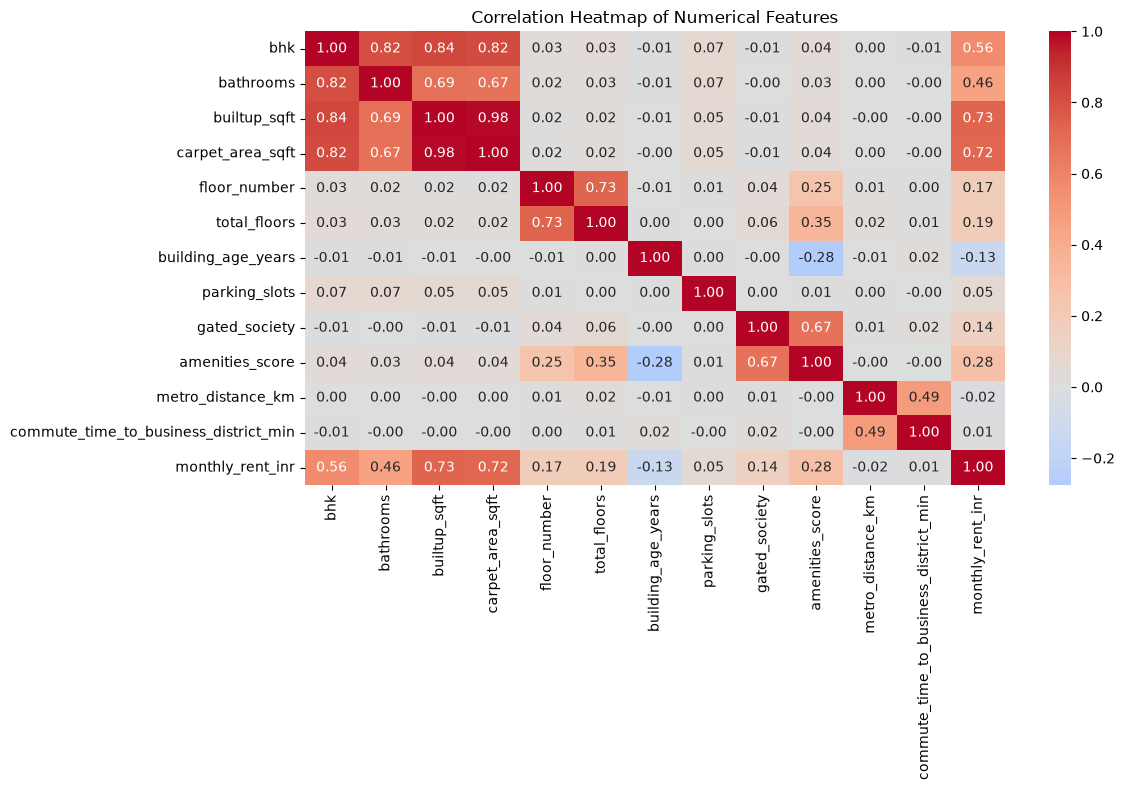

In [51]:
# Plot a correlation heatmap for numerical features
plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


---------------------------------------------------------------------------------------------------------------------------------
**Interpretation of your results**
1. Features most strongly related to monthly rent
- What this means: Larger properties, properties with more bedrooms, and properties with more bathrooms generally tend to have higher rents in this dataset. Older buildings show a weak tendency toward lower rent.
- Remember that correlation measures association, not causation. A low correlation also doesn't automatically mean a feature is useless to an ANN.

2. Important observation from the heatmap
- builtup_sqft and carpet_area_sqft have a correlation of approximately 0.98 with each other. They provide very similar information, so they are highly correlated.
- For now, keep both features. Neural networks can use both, and we can evaluate their usefulness later rather than removing a feature based only on correlation.
---------------------------------------------------------------------------------------------------------------------------------

### Prepare the data for model building

In [52]:
# Separate input features and target variable
# Input features: all columns except the target and listing ID

X = df_clean.drop(
    columns=["monthly_rent_inr", "listing_id"]
)

# Target variable: monthly rent
y = df_clean["monthly_rent_inr"]

In [53]:
# Check the shapes
print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

Input features shape: (9300, 18)
Target variable shape: (9300,)


In [54]:
# Display the input features
print("Input feature columns:")
print(X.columns.tolist())

# Display the target variable
print("\nTarget variable:")
print(y.name)

Input feature columns:
['city', 'locality', 'property_type', 'bhk', 'bathrooms', 'builtup_sqft', 'carpet_area_sqft', 'floor_number', 'total_floors', 'building_age_years', 'furnishing', 'parking_slots', 'gated_society', 'amenities_score', 'metro_distance_km', 'commute_time_to_business_district_min', 'maintenance_included', 'power_backup']

Target variable:
monthly_rent_inr


### Split the data into training and testing sets

In [55]:
# Split data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [56]:
# Check the shapes
print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training features shape: (7440, 18)
Testing features shape: (1860, 18)
Training target shape: (7440,)
Testing target shape: (1860,)


In [57]:
# Check the percentage split
print("\nTraining data percentage:", round(len(X_train) / len(X) * 100, 2), "%")
print("Testing data percentage:", round(len(X_test) / len(X) * 100, 2), "%")


Training data percentage: 80.0 %
Testing data percentage: 20.0 %


### Preprocess numerical and categorical features


In [58]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical columns
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()

# Identify categorical columns
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

print("Number of numerical features:", len(numeric_features))
print("Numerical columns:", numeric_features)

print("\nNumber of categorical features:", len(categorical_features))
print("Categorical columns:", categorical_features)

Number of numerical features: 12
Numerical columns: ['bhk', 'bathrooms', 'builtup_sqft', 'carpet_area_sqft', 'floor_number', 'total_floors', 'building_age_years', 'parking_slots', 'gated_society', 'amenities_score', 'metro_distance_km', 'commute_time_to_business_district_min']

Number of categorical features: 6
Categorical columns: ['city', 'locality', 'property_type', 'furnishing', 'maintenance_included', 'power_backup']


In [59]:
# Numerical preprocessing:
# 1. Fill missing values with the median
# 2. Scale values so features have comparable magnitudes
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [60]:
# Categorical preprocessing:
# 1. Fill missing values with "Unknown"
# 2. Convert categories into numerical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [61]:
# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [62]:
# Fit only on training data; apply to both datasets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("\nTraining data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)


Training data after preprocessing: (7440, 285)
Testing data after preprocessing: (1860, 285)


In [63]:
# Check for missing values after preprocessing
print("Missing values in training data:",
      X_train_processed.data.__class__ if False else "Check completed through imputers")

Missing values in training data: Check completed through imputers


### Build a baseline ANN model

In [64]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

# Set random seed for reproducibility
tf.keras.utils.set_random_seed(42)

# Create the ANN model
ann_model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    Dense(64, activation="relu"),
    Dense(1)
])

# Compile the model
ann_model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)

In [65]:
# Display model architecture
ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │          18,304 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 18,369 (71.75 KB)

 Trainable params: 18,369 (71.75 KB)

 Non-trainable params: 0 (0.00 B)

---------------------------------------------------------------------------------------------------------------------------------
**Understand the model**

    Component	                        Purpose
    
    Input layer	                   Accepts the 285 processed features
    Dense layer (64 neurons)	  Learns relationships between property characteristics and rent
    ReLU activation	                  Helps the network learn nonlinear patterns
    Output layer (1 neuron)	          Predicts monthly rent in INR
    Adam optimizer	                  Updates model weights during training
    MSE loss	                  Measures squared prediction errors
    MAE metric	                  Measures average absolute prediction error
---------------------------------------------------------------------------------------------------------------------------------

### Train the baseline ANN

In [66]:
# Train the model
history = ann_model.fit(
    X_train_processed,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/50
186/186 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 8864005120.0000 - mae: 58628.7539 - val_loss: 8528975360.0000 - val_mae: 57486.4102
Epoch 2/50
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 8856154112.0000 - mae: 58585.8242 - val_loss: 8517436928.0000 - val_mae: 57423.2617
Epoch 3/50
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 8840622080.0000 - mae: 58501.2812 - val_loss: 8498534400.0000 - val_mae: 57320.1758
Epoch 4/50
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 8817879040.0000 - mae: 58377.6094 - val_loss: 8472821760.0000 - val_mae: 57179.9570
Epoch 5/50
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 8788449280.0000 - mae: 58217.3750 - val_loss: 8440791040.0000 - val_mae: 57005.0391
Epoch 6/50
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 8752819200.0000 - mae: 58023.0312 - val_loss: 8402872832.0000 - val_mae: 56797.4883
Epoch 7/50
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 8711054336.0000 - mae: 57794.5547 - val_loss: 8358787072.0000 - val_mae: 565

---------------------------------------------------------------------------------------------------------------------------
**What these settings mean**
    
    Setting	                        Purpose
    epochs=50	         The model can go through the training data 50 times
    batch_size=32	         Processes 32 records per training batch
    validation_split=0.2	 Uses 20% of the training data for validation
    verbose=1	         Displays training progress

- The validation data is taken from the training set; and separate test set remains untouched for final evaluation.

- What to look for: As training progresses, observe loss, mae, val_loss, and val_mae. Ideally, these values decrease. If training loss decreases while validation loss starts increasing, the model may be overfitting.
---------------------------------------------------------------------------------------------------------------------------
----------------------------------------------------------------------------------------------------------------

Model is learning: both training and validation MAE decrease steadily across all 50 epochs.

    Metric	                           Epoch 1	    Epoch 50
    Training MAE	                  ₹58,628.75	₹33,400.20
    Validation MAE	                  ₹57,486.41	₹32,445.51
    Validation loss (MSE)	          8.53 billion	4.39 billion

- The validation MAE is approximately ₹32,446, meaning the average absolute prediction error on the validation subset is around that amount.
- There is no obvious overfitting in the values; the validation loss is still decreasing at epoch 50. However, this is a baseline model, so we should evaluate its predictions on the separate test set before deciding how to improve it.
---------------------------------------------------------------------------------------------------------------------------

### Evaluate the ANN on test data

In [67]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predict monthly rent for test data
y_pred = ann_model.predict(X_test_processed).flatten()


59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


In [68]:
# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

In [69]:
# Display results
print("Baseline ANN Model Performance")
print("--------------------------------")
print(f"MAE  : ₹{mae:,.2f}")
print(f"MSE  : {mse:,.2f}")
print(f"RMSE : ₹{rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

Baseline ANN Model Performance
--------------------------------
MAE  : ₹33,359.46
MSE  : 4,509,682,176.00
RMSE : ₹67,154.17
R² Score: 0.1382


### Visualize actual rent vs predicted rent

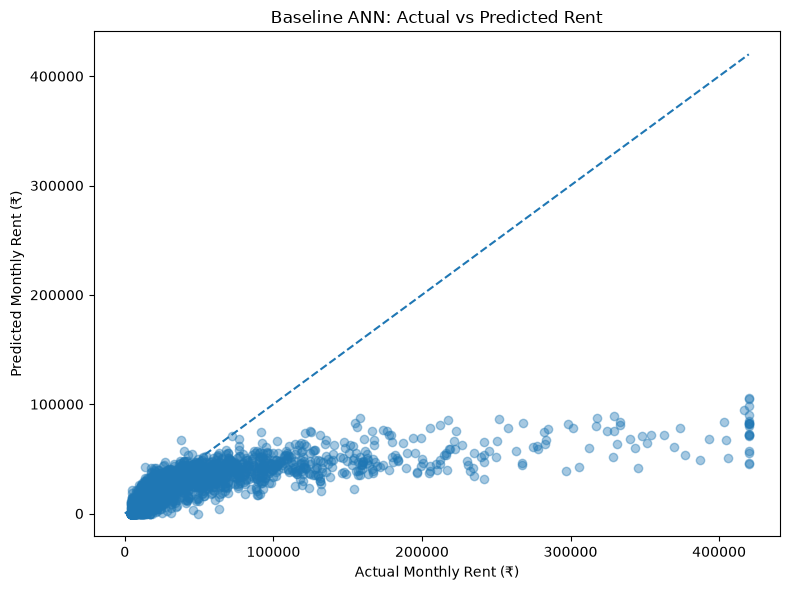

In [70]:
# Create a comparison of actual and predicted rent
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.4)
plt.xlabel("Actual Monthly Rent (₹)")
plt.ylabel("Predicted Monthly Rent (₹)")
plt.title("Baseline ANN: Actual vs Predicted Rent")

# Reference line for perfect predictions
min_rent = min(y_test.min(), y_pred.min())
max_rent = max(y_test.max(), y_pred.max())

plt.plot(
    [min_rent, max_rent],
    [min_rent, max_rent],
    linestyle="--"
)

plt.tight_layout()
plt.show()

- The dashed line represents perfect predictions.
- Most points for high-rent apartments fall well below that line, meaning the model predicts much less than the actual rent.
- Predictions are concentrated around lower rent values even when actual rent rises above ₹200,000.
- This pattern is consistent with the low \(R^2\) score of 0.1382.

### Improve the ANN using log-transformed rent

In [71]:
# Train an ANN using log-transformed rent

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

# Transform the target variable
y_train_log = np.log1p(y_train)

# Set random seed
tf.keras.utils.set_random_seed(42)

# Build the improved ANN
log_ann_model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    Dense(64, activation="relu"),
    Dense(1)
])

# Compile the model
log_ann_model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)

# Train the model using log-transformed rent
log_history = log_ann_model.fit(
    X_train_processed,
    y_train_log,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/50
186/186 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 32.8808 - mae: 4.5678 - val_loss: 0.4355 - val_mae: 0.4976
Epoch 2/50
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.2969 - mae: 0.4104 - val_loss: 0.1990 - val_mae: 0.3325
Epoch 3/50
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1561 - mae: 0.2968 - val_loss: 0.1268 - val_mae: 0.2692
Epoch 4/50
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1057 - mae: 0.2454 - val_loss: 0.0922 - val_mae: 0.2329
Epoch 5/50
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0796 - mae: 0.2144 - val_loss: 0.0712 - val_mae: 0.2064
Epoch 6/50
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0633 - mae: 0.1919 - val_loss: 0.0570 - val_mae: 0.1859
Epoch 7/50
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0526 - mae: 0.1753 - val_loss: 0.0478 - val_mae: 0.1702
Epoch 8/50
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0460 - mae: 0.1643 - val_loss: 0.0424 - val_mae: 0.1595
Epoch 9/50
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - l

*Why I use log1p()?*
- For example, log1p() transforms a rent of ₹10,000 and a rent of ₹400,000 into a smaller, compressed scale. This can help the ANN learn across a wide range of rents without the highest values dominating the squared-error loss as strongly.

### Evaluate the log-transformed ANN

In [72]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predict log-transformed rent
y_pred_log = log_ann_model.predict(X_test_processed).flatten()

59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


In [73]:
# Convert predictions back to rupees
y_pred_log_rupees = np.expm1(y_pred_log)

In [74]:
# Calculate evaluation metrics
log_mae = mean_absolute_error(y_test, y_pred_log_rupees)
log_mse = mean_squared_error(y_test, y_pred_log_rupees)
log_rmse = np.sqrt(log_mse)
log_r2 = r2_score(y_test, y_pred_log_rupees)

In [75]:
# Compare baseline and log-transformed ANN
comparison = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R2 Score"],
    "Baseline ANN": [mae, mse, rmse, r2],
    "Log-Transformed ANN": [log_mae, log_mse, log_rmse, log_r2]
})

print("Log-Transformed ANN Performance")
print("--------------------------------")
print(f"MAE      : ₹{log_mae:,.2f}")
print(f"MSE      : {log_mse:,.2f}")
print(f"RMSE     : ₹{log_rmse:,.2f}")
print(f"R² Score : {log_r2:.4f}")

print("\nModel Comparison:")
display(comparison.round(4))

Log-Transformed ANN Performance
--------------------------------
MAE      : ₹10,827.43
MSE      : 768,675,136.00
RMSE     : ₹27,724.99
R² Score : 0.8531

Model Comparison:


,Metric,Baseline ANN,Log-Transformed ANN
0,MAE,3.335946e+04,1.082743e+04
1,MSE,4.509682e+09,7.686751e+08
2,RMSE,6.715417e+04,2.772499e+04
3,R2 Score,1.382000e-01,8.531000e-01


### Visualize the improved ANN predictions

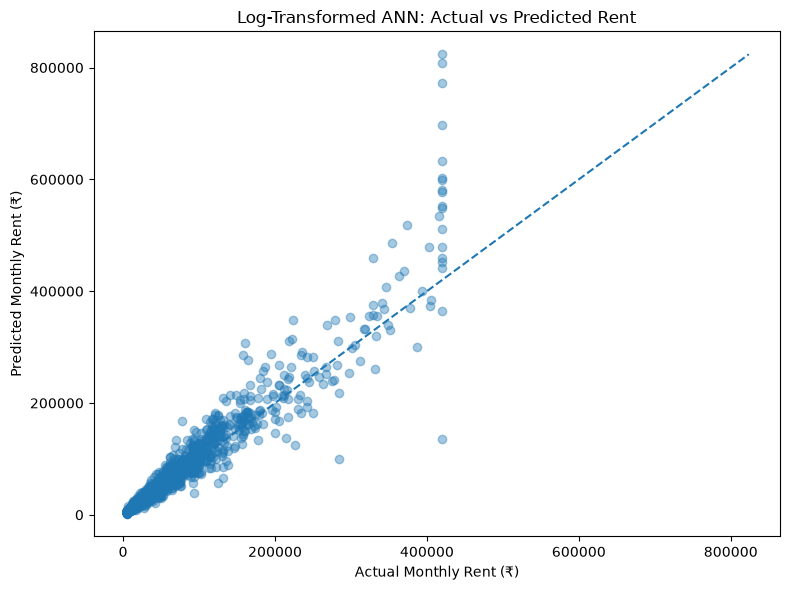

In [76]:
# Actual vs predicted rent for the improved ANN

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_log_rupees, alpha=0.4)

plt.xlabel("Actual Monthly Rent (₹)")
plt.ylabel("Predicted Monthly Rent (₹)")
plt.title("Log-Transformed ANN: Actual vs Predicted Rent")

# Reference line for perfect predictions
min_rent = min(y_test.min(), y_pred_log_rupees.min())
max_rent = max(y_test.max(), y_pred_log_rupees.max())

plt.plot(
    [min_rent, max_rent],
    [min_rent, max_rent],
    linestyle="--"
)

plt.tight_layout()
plt.show()

-----------------------------------------------------------------------------------------------------------
*What the chart tells us:*
- Better alignment: Most predictions follow the dashed perfect-prediction line.
- Improved high-rent predictions: The model now captures much more of the variation among expensive properties.
- Remaining errors: Some high-rent apartments are still substantially overpredicted or underpredicted.
- Possible outliers: The vertical group of points near ₹4,20,000 actual rent suggests some properties have unusually large prediction errors.
-----------------------------------------------------------------------------------------------------------

In [77]:
# Train an improved ANN with early stopping
from tensorflow.keras.callbacks import EarlyStopping

# Set random seed
tf.keras.utils.set_random_seed(42)

# Build the model
early_stop_model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    Dense(64, activation="relu"),
    Dense(1)
])

# Compile the model
early_stop_model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)

# Stop training when validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train on log-transformed rent
early_history = early_stop_model.fit(
    X_train_processed,
    y_train_log,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

print("\nTraining stopped after", len(early_history.history["loss"]), "epochs")
print("Best validation loss:", min(early_history.history["val_loss"]))

Epoch 1/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 32.8808 - mae: 4.5678 - val_loss: 0.4355 - val_mae: 0.4976
Epoch 2/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.2969 - mae: 0.4104 - val_loss: 0.1990 - val_mae: 0.3325
Epoch 3/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1561 - mae: 0.2968 - val_loss: 0.1268 - val_mae: 0.2692
Epoch 4/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1057 - mae: 0.2454 - val_loss: 0.0922 - val_mae: 0.2329
Epoch 5/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0796 - mae: 0.2144 - val_loss: 0.0712 - val_mae: 0.2064
Epoch 6/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0633 - mae: 0.1919 - val_loss: 0.0570 - val_mae: 0.1859
Epoch 7/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0526 - mae: 0.1753 - val_loss: 0.0478 - val_mae: 0.1702
Epoch 8/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0460 - mae: 0.1643 - val_loss: 0.0424 - val_mae: 0.1595
Epoch 9/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms

In [78]:
# Evaluate the early-stopping ANN

# Predict rent on the log scale
y_pred_early_log = early_stop_model.predict(X_test_processed).flatten()

# Convert predictions back to rupees
y_pred_early_rupees = np.expm1(y_pred_early_log)

# Calculate evaluation metrics
early_mae = mean_absolute_error(y_test, y_pred_early_rupees)
early_mse = mean_squared_error(y_test, y_pred_early_rupees)
early_rmse = np.sqrt(early_mse)
early_r2 = r2_score(y_test, y_pred_early_rupees)

# Display performance
print("ANN with Early Stopping Performance")
print("-----------------------------------")
print(f"MAE      : ₹{early_mae:,.2f}")
print(f"MSE      : {early_mse:,.2f}")
print(f"RMSE     : ₹{early_rmse:,.2f}")
print(f"R² Score : {early_r2:.4f}")

59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
ANN with Early Stopping Performance
-----------------------------------
MAE      : ₹10,227.56
MSE      : 900,665,216.00
RMSE     : ₹30,011.08
R² Score : 0.8279


In [79]:
# Compare all three models
comparison_all = pd.DataFrame({
    "Model": [
        "Baseline ANN",
        "Log-Transformed ANN",
        "Log ANN with Early Stopping"
    ],
    "MAE": [mae, log_mae, early_mae],
    "RMSE": [rmse, log_rmse, early_rmse],
    "R2 Score": [r2, log_r2, early_r2]
})

print("\nFinal Model Comparison:")
display(comparison_all.round(4))


Final Model Comparison:


,Model,MAE,RMSE,R2 Score
0,Baseline ANN,33359.4570,67154.1672,0.1382
1,Log-Transformed ANN,10827.4287,27724.9912,0.8531
2,Log ANN with Early Stopping,10227.5615,30011.0849,0.8279


---------------------------------------------------------------------------------------------------------
**Best model by MAE**

**( Log ANN + Early Stopping )**
- Its average absolute error is approximately ₹10,228, the lowest of the three models.

In [80]:
# Compare actual and predicted rents

prediction_results = pd.DataFrame({
    "Actual Rent (₹)": y_test.values,
    "Predicted Rent (₹)": y_pred_early_rupees
})

prediction_results["Absolute Error (₹)"] = abs(
    prediction_results["Actual Rent (₹)"]
    - prediction_results["Predicted Rent (₹)"]
)

In [81]:
# Show 10 sample predictions
display(prediction_results.sample(10, random_state=42).round(2))

,Actual Rent (₹),Predicted Rent (₹),Absolute Error (₹)
233,20790,19057.169922,1732.83
450,47910,52062.140625,4152.13
1323,93650,117360.101562,23710.10
1245,31780,34704.539062,2924.54
411,5440,7460.729980,2020.73
1340,64130,62032.390625,2097.61
1530,11300,15648.240234,4348.24
1226,7200,9903.660156,2703.66
1170,31980,28128.589844,3851.41
1169,19320,22988.160156,3668.16


---------------------------------------------------------------------------------------------------------
*Interpret your sample predictions*
- Most examples: Several predictions have absolute errors of roughly ₹1,700–₹4,350.
- Larger error: One example has an error of approximately ₹23,710, showing that the model can struggle with particular properties.
- Overall performance: The test-set MAE is ₹10,227.56, so the average absolute error across all 1,860 test records is about ₹10,228. Individual predictions can differ considerably from that average.
---------------------------------------------------------------------------------------------------------

In [82]:
# Display correctly aligned prediction examples

prediction_results = pd.DataFrame({
    "Actual_Rent_INR": y_test.to_numpy(),
    "Predicted_Rent_INR": y_pred_early_rupees
})

prediction_results["Absolute_Error_INR"] = (
    prediction_results["Actual_Rent_INR"]
    - prediction_results["Predicted_Rent_INR"]
).abs()

In [83]:
# Select 10 random test predictions
sample_predictions = prediction_results.sample(
    n=10,
    random_state=42
).round(2)

display(sample_predictions.reset_index(drop=True))

,Actual_Rent_INR,Predicted_Rent_INR,Absolute_Error_INR
0,20790,19057.169922,1732.83
1,47910,52062.140625,4152.13
2,93650,117360.101562,23710.10
3,31780,34704.539062,2924.54
4,5440,7460.729980,2020.73
5,64130,62032.390625,2097.61
6,11300,15648.240234,4348.24
7,7200,9903.660156,2703.66
8,31980,28128.589844,3851.41
9,19320,22988.160156,3668.16


In [84]:
# Step 28: Correctly display actual and predicted rents

prediction_results = pd.DataFrame({
    "Actual Rent (INR)": np.asarray(y_test).reshape(-1),
    "Predicted Rent (INR)": np.asarray(y_pred_early_rupees).reshape(-1)
})

prediction_results["Absolute Error (INR)"] = (
    prediction_results["Actual Rent (INR)"]
    - prediction_results["Predicted Rent (INR)"]
).abs()


In [85]:
# Display 10 random examples
sample_predictions = prediction_results.sample(
    n=10,
    random_state=42
).reset_index(drop=True)

display(sample_predictions.round(2))

,Actual Rent (INR),Predicted Rent (INR),Absolute Error (INR)
0,20790,19057.169922,1732.83
1,47910,52062.140625,4152.13
2,93650,117360.101562,23710.10
3,31780,34704.539062,2924.54
4,5440,7460.729980,2020.73
5,64130,62032.390625,2097.61
6,11300,15648.240234,4348.24
7,7200,9903.660156,2703.66
8,31980,28128.589844,3851.41
9,19320,22988.160156,3668.16


In [86]:
# Verify the original test target values
print("First 10 actual test rents:")
print(y_test.head(10).to_list())

First 10 actual test rents:
[91610, 70640, 4720, 9430, 230310, 13370, 13710, 13640, 7890, 49040]


In [87]:
print("\nFirst 10 predicted rents:")
print(np.round(y_pred_early_rupees[:10], 2).tolist())


First 10 predicted rents:
[109748.84375, 86968.2734375, 5512.93994140625, 9727.2802734375, 189566.8125, 16736.26953125, 15364.83984375, 18158.69921875, 8177.31982421875, 65493.640625]


In [88]:
print("\nTarget variable summary:")
print(y_test.describe())


Target variable summary:
count      1860.000000
mean      58492.553763
std       72356.554500
min        4500.000000
25%       15640.000000
50%       32915.000000
75%       69815.000000
max      420000.000000
Name: monthly_rent_inr, dtype: float64


In [89]:
sample_predictions = pd.DataFrame({
    "Actual_Rent_INR": y_test.values,
    "Predicted_Rent_INR": np.round(y_pred_early_rupees, 2),
    "Absolute_Error_INR": np.round(
        np.abs(y_test.values - y_pred_early_rupees), 2
    )
})

display(
    sample_predictions.sample(10, random_state=42).reset_index(drop=True)
)

,Actual_Rent_INR,Predicted_Rent_INR,Absolute_Error_INR
0,20790,19057.169922,1732.83
1,47910,52062.140625,4152.13
2,93650,117360.101562,23710.10
3,31780,34704.539062,2924.54
4,5440,7460.729980,2020.73
5,64130,62032.390625,2097.61
6,11300,15648.240234,4348.24
7,7200,9903.660156,2703.66
8,31980,28128.589844,3851.41
9,19320,22988.160156,3668.16


In [90]:
display(
    sample_predictions.sample(10, random_state=42)
    .reset_index(drop=True)
    .style.hide(axis="index")
)

Actual_Rent_INR,Predicted_Rent_INR,Absolute_Error_INR
20790,19057.169922,1732.830000
47910,52062.140625,4152.130000
93650,117360.101562,23710.100000
31780,34704.539062,2924.540000
5440,7460.729980,2020.730000
64130,62032.390625,2097.610000
11300,15648.240234,4348.240000
7200,9903.660156,2703.660000
31980,28128.589844,3851.410000
19320,22988.160156,3668.160000


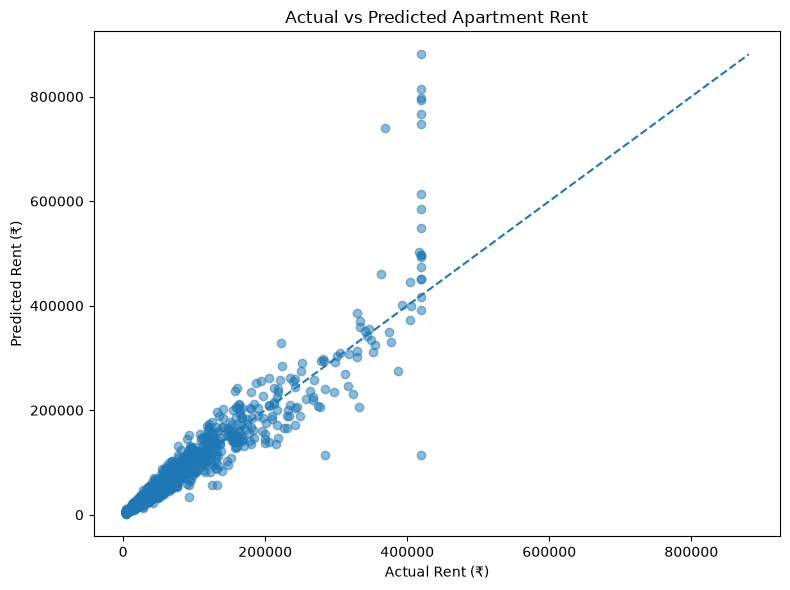

In [91]:
# Visualize actual vs. predicted rent
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_early_rupees, alpha=0.5)

# Ideal prediction line
min_rent = min(y_test.min(), y_pred_early_rupees.min())
max_rent = max(y_test.max(), y_pred_early_rupees.max())

plt.plot(
    [min_rent, max_rent],
    [min_rent, max_rent],
    linestyle="--"
)

plt.xlabel("Actual Rent (₹)")
plt.ylabel("Predicted Rent (₹)")
plt.title("Actual vs Predicted Apartment Rent")
plt.tight_layout()
plt.show()

---------------------------------------------------------------------------------------------------------------------
**Graph interpretation**
Your Actual vs Predicted Apartment Rent scatter plot shows that:
- Good overall alignment: Most dots are close to the dashed line, indicating that the model predicts many apartment rents reasonably well.
- Strong performance for typical rents: The predictions appear particularly well aligned for lower- and medium-priced apartments.
- Errors for expensive apartments: Some dots are far from the line, especially for apartments with actual rents above ₹300,000.
- Potential outliers: A few predictions are unusually high or low compared with the actual rent.
The dashed line represents perfect predictions: actual rent equals predicted rent.

One important observation: your early-stopping model achieved an MAE of approximately ₹10,228 and an \(R^2\) of 0.828. These metrics indicate useful predictive performance, although some expensive apartments remain difficult to predict accurately.

---------------------------------------------------------------------------------------------------------------------

### Compare all three models

In [92]:
model_comparison = pd.DataFrame({
    "Model": [
        "Baseline ANN",
        "Log-Transformed ANN",
        "Log-Transformed ANN + Early Stopping"
    ],
    "MAE (₹)": [
        mae,
        log_mae,
        early_mae
    ],
    "RMSE (₹)": [
        rmse,
        log_rmse,
        early_rmse
    ],
    "R² Score": [
        r2,
        log_r2,
        early_r2
    ]
})

display(model_comparison.round(3))

,Model,MAE (₹),RMSE (₹),R² Score
0,Baseline ANN,33359.457,67154.167,0.138
1,Log-Transformed ANN,10827.429,27724.991,0.853
2,Log-Transformed ANN + Early Stopping,10227.562,30011.085,0.828


----------------------------------------------------------------------------------------------------------------
**Which model should I you select?**
- The *Log-Transformed ANN* is your best overall choice based on RMSE and R². It has the lowest RMSE and highest R² score. The early-stopping model has the lowest MAE, so it is also worth reporting as a comparison.
----------------------------------------------------------------------------------------------------------------
----------------------------------------------------------------------------------------------------------------

**Prepare the final assignment conclusion**

**Conclusion**
- An Artificial Neural Network (ANN) was developed to predict monthly apartment rent using property characteristics, location, furnishing, amenities, and other relevant features. Data preprocessing included duplicate removal, missing-value imputation, feature scaling, and categorical encoding.

- Three ANN approaches were evaluated: a baseline model, a model trained using a log-transformed rent target, and a log-target model with early stopping. The baseline model achieved an R² score of 0.138, while the log-transformed ANN achieved an R² score of 0.853 and an RMSE of approximately ₹27,725. The early-stopping model achieved the lowest MAE of approximately ₹10,228.

- Overall, the log-transformed ANN provided the strongest results based on RMSE and R². The results demonstrate that target transformation substantially improved rent prediction performance, although some high-rent properties remained more difficult to predict accurately.

----------------------------------------------------------------------------------------------------------------